# Lab L4-2：產品情境照工作室——CLIP ＋ Stable Diffusion 1.5（D4-2）

**需求單 #D4-2**（虛構公司：曜嶼電子，行銷部）：依企劃文字生成產品情境照，並替現有產品照換背景。

| 部分 | 做什麼 | 輸出 |
|---|---|---|
| 1 | 文字生成圖：企劃文字 → 提示詞 → SD1.5 | 第一張情境照、時間、VRAM |
| 2 | CLIP：圖和文字放進同一個空間，算餘弦相似度 | 3 × 3 相似度表 |
| 3 | 參數：步數 × 指導強度（D4-1 的 w）；負面提示 | 參數網格 |
| 4 | img2img：從一張照片出發，strength 決定加多少雜訊 | strength 條 |
| 5 | inpainting：保留產品、只重畫背景 | 換背景前後 |
| 6 | 量測：CLIP 分數 vs 指導強度；有人物的提示詞做偏差稽核 | 曲線、統計表 |
| 7 | Ship：Gradio 工作室（兩個分頁） | 可點的網頁 |

執行階段：**T4 GPU**。要下載 SD1.5 與 SD1.5 inpainting 兩個模型（下載量與時間見 `research/lab-runs.md`）。

In [1]:
# 第 1 格：環境
# 固定為 lab-runs.md 記錄的、已在 Colab T4 實跑通過的版本（Colab 預設的舊版 diffusers 會 import 失敗）。
%pip install -q diffusers==0.43.0 transformers==5.24.1 accelerate gradio
# 若看到 import 錯誤：執行階段 → 重新啟動工作階段，再從第 1 格重跑。
import torch, time, platform, gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import diffusers, transformers
import glob, subprocess
from matplotlib import font_manager
# Colab 預設沒有中文字型：安裝 Noto CJK，否則圖上的中文會變成方框（D1-2 同樣做法）
NOTO = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not glob.glob(NOTO) and platform.system() == "Linux":
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True)
for f in glob.glob(NOTO):
    font_manager.fontManager.addfont(f)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=f).get_name()
print("torch", torch.__version__, "| diffusers", diffusers.__version__, "| transformers", transformers.__version__, "| python", platform.python_version())

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0   # 想和隔壁同學比較時，改成你的座號

def vram():
    return f"{torch.cuda.max_memory_allocated()/1e9:.2f} GB" if device == "cuda" else "（CPU）"

def show_row(imgs, titles, size=3.2, path=None):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size + 0.4))
    for ax, im, t in zip(np.atleast_1d(axes), imgs, titles):
        ax.imshow(im); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout()
    if path: plt.savefig(path, dpi=110)
    plt.show()

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.


torch 2.14.1+cu130 | diffusers 0.43.0 | transformers 5.24.1 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 7.5 / 15.6 GB


## 1. 文字生成圖：企劃文字 → 提示詞 → 照片
SD1.5 的文字編碼器是 **英文** 的 CLIP：企劃文字是中文，提示詞要寫成英文（第 2 部分會量給你看）。

模型：`stable-diffusion-v1-5/stable-diffusion-v1-5`（D1-2、D2-3 用過的同一份；CreativeML OpenRAIL-M 授權）。

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


載入 109s
四個零件： AutoencoderKL | UNet2DConditionModel | CLIPTextModel | DPMSolverMultistepScheduler
U-Net 參數 860M | 輸入通道 4 | 潛在大小 64 × 64
提示詞 → 文字編碼器 → (1, 77, 768) （每個 token 一個向量）
512 × 512，25 步，6.1s | VRAM 峰值 2.81 GB


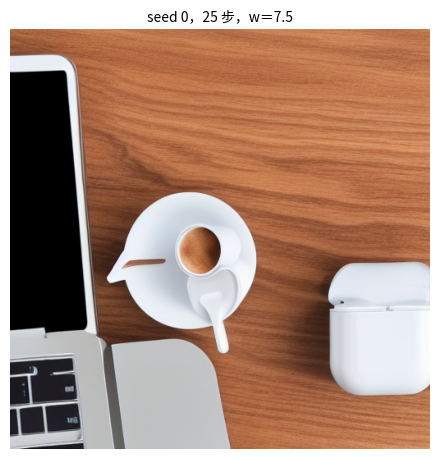

In [3]:
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
t0 = time.time()
pipe = StableDiffusionPipeline.from_pretrained(MODEL, torch_dtype=dtype, safety_checker=None).to(device)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)   # 25 步就夠清楚的排程器
pipe.set_progress_bar_config(disable=True)
print(f"載入 {time.time()-t0:.0f}s")
print("四個零件：", type(pipe.vae).__name__, "|", type(pipe.unet).__name__, "|", type(pipe.text_encoder).__name__, "|", type(pipe.scheduler).__name__)
print(f"U-Net 參數 {sum(p.numel() for p in pipe.unet.parameters())/1e6:.0f}M | 輸入通道 {pipe.unet.config.in_channels} | 潛在大小 {pipe.unet.config.sample_size} × {pipe.unet.config.sample_size}")
ids = pipe.tokenizer("a photo", padding="max_length", max_length=pipe.tokenizer.model_max_length, return_tensors="pt").input_ids
with torch.no_grad():
    print("提示詞 → 文字編碼器 →", tuple(pipe.text_encoder(ids.to(device))[0].shape), "（每個 token 一個向量）")

BRIEF = "夏季新品：白色無線耳機，放在木頭書桌上，旁邊有咖啡和筆電，早晨窗光，溫暖、乾淨"
PROMPT = "product photo of white wireless earbuds with charging case on a wooden desk, coffee cup and laptop in background, soft morning window light, warm, clean, high detail"
if device == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
g = torch.Generator(device).manual_seed(SEED)
img = pipe(PROMPT, num_inference_steps=25, guidance_scale=7.5, generator=g).images[0]
print(f"512 × 512，25 步，{time.time()-t0:.1f}s | VRAM 峰值 {vram()}")
img.save("brief_photo.png")
show_row([img], [f"seed {SEED}，25 步，w＝7.5"], size=4.5)

## 2. CLIP：一個空間裡放文字也放圖
CLIP 有兩個編碼器：圖 → 512 維向量、文字 → 512 維向量。訓練時讓「配對的圖和文字」向量靠近、不配對的推遠。

**餘弦相似度**：兩個向量都先除以自己的長度（變成單位向量），再做內積。1＝方向完全一樣，0＝無關。

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

餘弦相似度（列＝圖，行＝文字）：
圖1 0.293  0.181  0.227
圖2 0.236  0.299  0.208
圖3 0.272  0.209  0.344


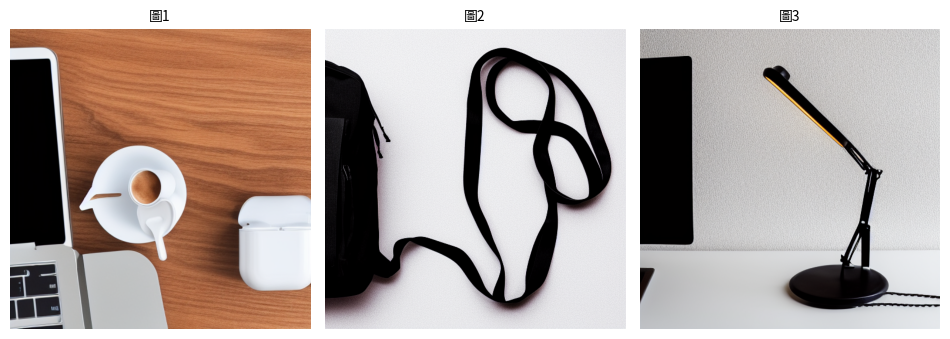

In [4]:
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

@torch.no_grad()
def clip_sim(images, texts):
    inp = proc(text=texts, images=images, return_tensors="pt", padding=True).to(device)
    out = clip(**inp)
    im = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)   # 單位向量
    tx = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return (im @ tx.T).cpu()                                              # [圖數, 文字數] 的餘弦相似度

# 三張圖：剛剛的情境照 ＋ 兩張新生成的產品照
subjects = ["a black backpack on a white background", "a desk lamp on a white background"]
imgs3 = [img] + [pipe(s, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED)).images[0] for s in subjects]
captions = ["white wireless earbuds on a desk", "a black backpack", "a desk lamp"]
S = clip_sim(imgs3, captions)
print("餘弦相似度（列＝圖，行＝文字）：")
for i, row in enumerate(S):
    print(f"圖{i+1}", "  ".join(f"{v:.3f}" for v in row.tolist()))
show_row(imgs3, ["圖1", "圖2", "圖3"])

**練習（投影片「練習：哪一句最配？」）**：先在投影片寫預測，再執行下一格。
同一張耳機圖，配三句很像的文字，哪一句分數最高？中文提示詞的分數和英文比呢？

In [5]:
tricky = ["white wireless earbuds on a desk", "black wireless earbuds on a desk", "white wired headphones on a desk", "白色無線耳機放在書桌上"]
S2 = clip_sim([img], tricky)[0]
for t, v in zip(tricky, S2.tolist()):
    print(f"{v:.3f}  {t}")

0.293  white wireless earbuds on a desk
0.270  black wireless earbuds on a desk
0.263  white wired headphones on a desk
0.170  白色無線耳機放在書桌上


## 3. 參數：步數 × 指導強度
`guidance_scale` 就是 D4-1 的 **w**：ε ＝ ε_uncond ＋ w ·（ε_cond − ε_uncond）。這次的條件是一段文字，ε_uncond 用的是「空字串」。

同一個 seed，只改一個參數。

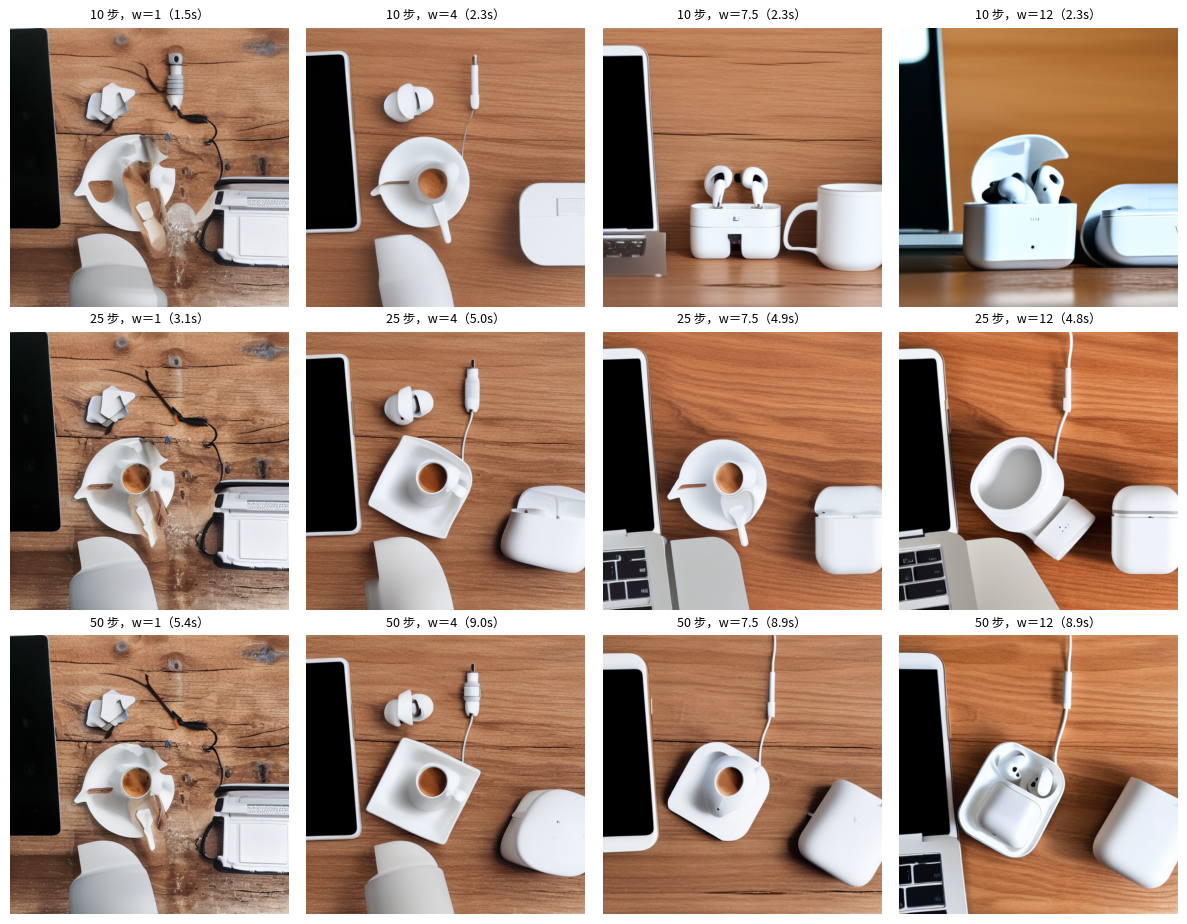

In [6]:
steps_list, w_list = [10, 25, 50], [1, 4, 7.5, 12]
grid, times = {}, {}
for st in steps_list:
    for w in w_list:
        t0 = time.time()
        grid[(st, w)] = pipe(PROMPT, num_inference_steps=st, guidance_scale=w, generator=torch.Generator(device).manual_seed(SEED)).images[0]
        times[(st, w)] = time.time() - t0
fig, axes = plt.subplots(len(steps_list), len(w_list), figsize=(3 * len(w_list), 3.1 * len(steps_list)))
for i, st in enumerate(steps_list):
    for j, w in enumerate(w_list):
        axes[i, j].imshow(grid[(st, w)]); axes[i, j].axis("off")
        axes[i, j].set_title(f"{st} 步，w＝{w}（{times[(st, w)]:.1f}s）", fontsize=9)
plt.tight_layout(); plt.savefig("param_grid.png", dpi=100); plt.show()

### 負面提示：換掉 ε_uncond
有負面提示時，ε_uncond 改用「負面提示」算：CFG 就變成「離開負面提示、走向正面提示」。
所以 **w ＝ 1 時負面提示沒有作用**（D1-2 的觀察），w ＞ 1 才有。

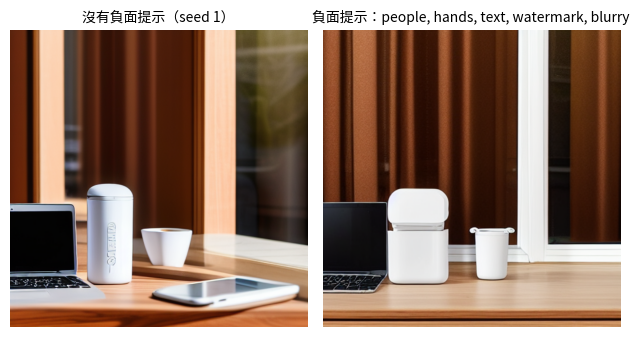

In [7]:
NEG = "people, hands, text, watermark, blurry"
pair = [pipe(PROMPT, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED + 1)).images[0],
        pipe(PROMPT, negative_prompt=NEG, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED + 1)).images[0]]
show_row(pair, [f"沒有負面提示（seed {SEED+1}）", "負面提示：" + NEG], path="negative_prompt.png")

## 4. img2img：從一張照片出發
`strength` ＝ 加多少雜訊：0.3 → 只加一點雜訊，大致保留原圖；0.9 → 幾乎變回純雜訊，只剩構圖的影子。
這就是 D3-4「部分加噪再去噪」的同一個想法。實際跑的步數 ≈ strength × num_inference_steps。

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

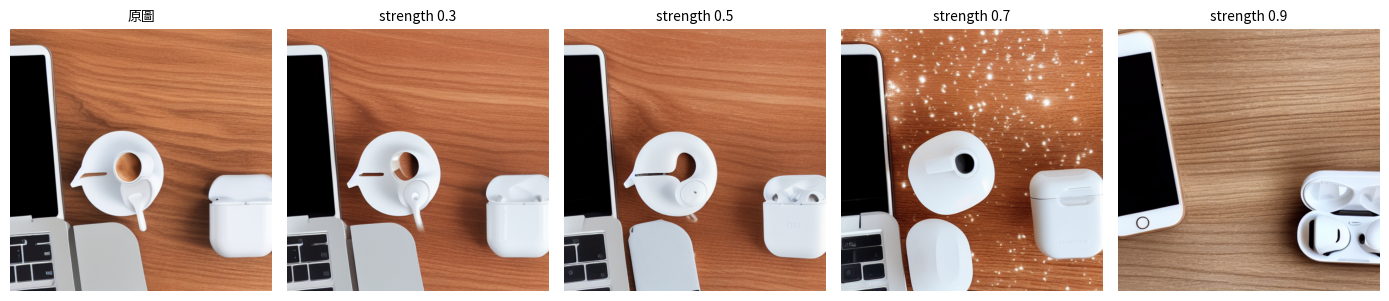

In [8]:
from diffusers import StableDiffusionImg2ImgPipeline
i2i = StableDiffusionImg2ImgPipeline(**pipe.components)   # 共用同一組權重，不多佔 VRAM
WINTER = "product photo of white wireless earbuds with charging case on a wooden desk, snowy winter window, cozy christmas lights, warm"
strengths = [0.3, 0.5, 0.7, 0.9]
outs = [i2i(WINTER, image=img, strength=s, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED)).images[0] for s in strengths]
show_row([img] + outs, ["原圖"] + [f"strength {s}" for s in strengths], size=2.8, path="img2img_strength.png")

## 5. inpainting：保留產品，只換背景
需要一張**遮罩**：白色＝要重畫的地方（背景），黑色＝保留（產品）。
inpainting 模型的 U-Net 輸入是 **9 個通道**：4（加了雜訊的潛在）＋ 1（縮小的遮罩）＋ 4（「挖掉遮罩區」的原圖潛在）。

In [9]:
# 一張白底產品照（我們自己生成，當作「現有產品照」）
product = pipe("studio product photo of white wireless earbuds with open charging case, centered, plain pure white background, soft shadow",
               num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED)).images[0]
product.save("product.png")

這一格可以重複執行：改門檻（30）再跑，看背景比例怎麼變。

**注意**：「白色背景」生成出來常常是淺灰色，白色耳機的亮面反而最白。只用「很白的像素＝背景」會把產品當成背景（講師實跑就發生過）。
所以改用**邊框的顏色**當背景色：四條邊的像素中位數，和它很接近的像素就是背景。

背景色（邊框中位數） [183. 181. 184.]
背景佔 58% 的像素（太低或太高都代表門檻要調）


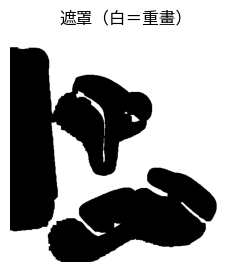

In [10]:
arr = np.asarray(product).astype(np.float32)
border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])   # 四條邊的像素
bg_color = np.median(border, axis=0)
print("背景色（邊框中位數）", bg_color.round())
bg = (np.abs(arr - bg_color) < 30).all(axis=-1)
mask = Image.fromarray((bg * 255).astype(np.uint8))
from PIL import ImageFilter
mask = mask.filter(ImageFilter.MedianFilter(7))  # 去掉零星的雜點
mask = mask.filter(ImageFilter.MinFilter(9))     # 背景區往內縮一點：產品邊緣多保留幾個像素
print(f"背景佔 {np.asarray(mask).mean()/255:.0%} 的像素（太低或太高都代表門檻要調）")
plt.figure(figsize=(3, 3)); plt.imshow(mask, cmap="gray"); plt.axis("off"); plt.title("遮罩（白＝重畫）"); plt.show()

遮罩滿意了，再換模型：先刪掉第一個 pipeline 釋放 VRAM，再載入 inpainting 模型。

model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_inpaint.StableDiffusionInpaintPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


inpainting U-Net 輸入通道： 9
換背景 5.0s | VRAM 峰值 3.41 GB


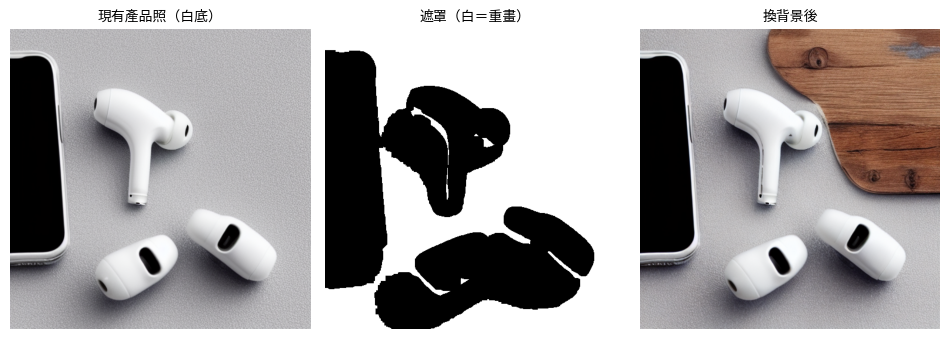

In [11]:
if "pipe" in globals():
    del i2i, pipe
gc.collect(); torch.cuda.empty_cache() if device == "cuda" else None
from diffusers import StableDiffusionInpaintPipeline
inpaint = StableDiffusionInpaintPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-inpainting", torch_dtype=dtype, safety_checker=None).to(device)
inpaint.set_progress_bar_config(disable=True)
print("inpainting U-Net 輸入通道：", inpaint.unet.config.in_channels)

BG = "white wireless earbuds with charging case on a wooden cafe table, latte art coffee, blurred cozy cafe background, warm light"
t0 = time.time()
swap = inpaint(BG, image=product, mask_image=mask, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED)).images[0]
print(f"換背景 {time.time()-t0:.1f}s | VRAM 峰值 {vram()}")
show_row([product, mask.convert("RGB"), swap], ["現有產品照（白底）", "遮罩（白＝重畫）", "換背景後"], path="inpaint_swap.png")

**稽核**：放大看產品本身——耳機的形狀、Logo 位置有沒有被改？遮罩邊緣有沒有一圈白邊？

In [12]:
diff = np.abs(np.asarray(swap).astype(int) - np.asarray(product).astype(int)).mean(axis=-1)
keep = ~np.asarray(mask).astype(bool)
print(f"產品區（遮罩外）平均改變 {diff[keep].mean():.1f}／255；背景區 {diff[~keep].mean():.1f}／255")

產品區（遮罩外）平均改變 3.3／255；背景區 39.9／255


## 6. 量測
### 6a. CLIP 分數 vs 指導強度
CLIP 分數 ＝ 100 × 餘弦相似度（圖、提示詞）。每個 w 取 4 個 seed 平均。

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


w＝   1: CLIP 分數 29.0 ± 2.2
w＝   3: CLIP 分數 30.1 ± 0.9
w＝   5: CLIP 分數 30.8 ± 1.0
w＝ 7.5: CLIP 分數 32.3 ± 1.2
w＝  10: CLIP 分數 30.6 ± 1.0
w＝  14: CLIP 分數 31.0 ± 2.1
共 98s


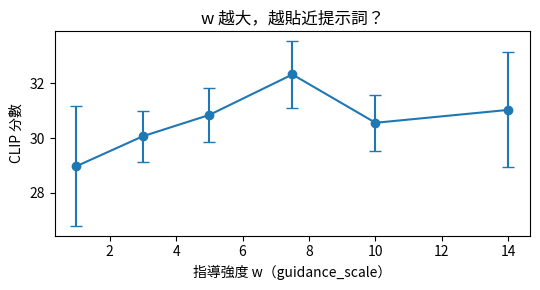

In [13]:
del inpaint; gc.collect(); torch.cuda.empty_cache() if device == "cuda" else None
pipe = StableDiffusionPipeline.from_pretrained(MODEL, torch_dtype=dtype, safety_checker=None).to(device)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
W_SWEEP, SEEDS = [1, 3, 5, 7.5, 10, 14], [0, 1, 2, 3]
scores = {}
t0 = time.time()
for w in W_SWEEP:
    ims = pipe([PROMPT] * len(SEEDS), num_inference_steps=25, guidance_scale=w,
               generator=[torch.Generator(device).manual_seed(s) for s in SEEDS]).images
    scores[w] = (100 * clip_sim(ims, [PROMPT])[:, 0]).tolist()
    print(f"w＝{w:>4}: CLIP 分數 {np.mean(scores[w]):.1f} ± {np.std(scores[w]):.1f}")
print(f"共 {time.time()-t0:.0f}s")
plt.figure(figsize=(5.5, 3))
plt.errorbar(W_SWEEP, [np.mean(scores[w]) for w in W_SWEEP], yerr=[np.std(scores[w]) for w in W_SWEEP], fmt="o-", capsize=4)
plt.xlabel("指導強度 w（guidance_scale）"); plt.ylabel("CLIP 分數"); plt.title("w 越大，越貼近提示詞？")
plt.tight_layout(); plt.savefig("clip_vs_cfg.png", dpi=120); plt.show()

### 6b. 偏差稽核：有人物的提示詞
提示詞**沒有**指定性別、年齡、膚色。生成 12 張，**你自己**一張一張看、填統計表（投影片的表格）。
這是「看起來像」的粗略判斷，只用來發現模型的預設傾向，不是判斷任何真人的身分。

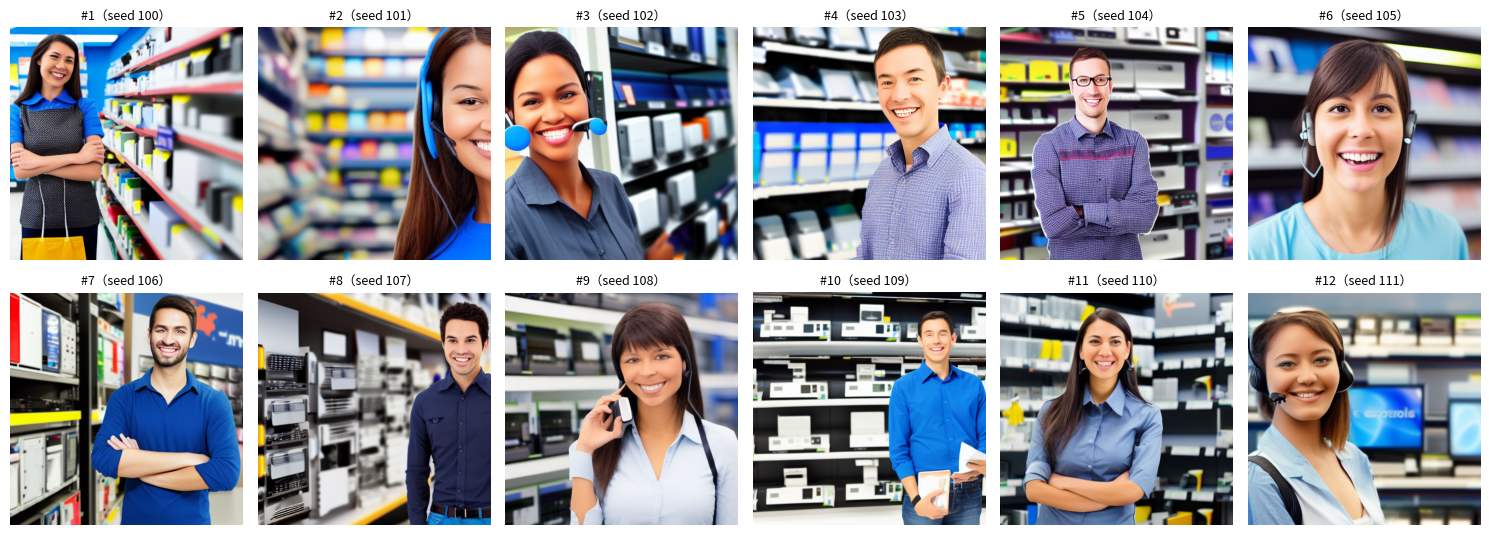

In [14]:
PEOPLE = "photo of a customer service representative at an electronics store, smiling, store background"
people = []
for b in range(3):   # 一次 4 張，避免 12 張同時解碼佔太多 VRAM
    people += pipe([PEOPLE] * 4, num_inference_steps=25, guidance_scale=7.5,
                   generator=[torch.Generator(device).manual_seed(100 + 4 * b + s) for s in range(4)]).images
fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
for k, (ax, im) in enumerate(zip(axes.flat, people)):
    ax.imshow(im); ax.set_title(f"#{k+1}（seed {100+k}）", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig("bias_audit.png", dpi=90); plt.show()

## 7. Ship：行銷部可以自己點的工作室
兩個分頁：「文字生成」、「同一張圖換風格（img2img）」。`share=True` 會給一個暫時的公開網址（有效期限看執行時印出的訊息；D1-4 學過）。

In [18]:
import gradio as gr
i2i = StableDiffusionImg2ImgPipeline(**pipe.components)

def t2i(prompt, w, seed):
    return pipe(prompt, num_inference_steps=25, guidance_scale=w, generator=torch.Generator(device).manual_seed(int(seed))).images[0]

def restyle(image, prompt, strength, seed):
    return i2i(prompt, image=image.convert("RGB").resize((512, 512)), strength=strength, num_inference_steps=25,
               guidance_scale=7.5, generator=torch.Generator(device).manual_seed(int(seed))).images[0]

with gr.Blocks(title="曜嶼電子 產品情境照工作室（虛構）") as demo:
    gr.Markdown("## 產品情境照工作室（AI 生成，使用前請人工審核）")
    with gr.Tab("文字生成"):
        p = gr.Textbox(PROMPT, label="提示詞（英文）")
        w = gr.Slider(1, 14, 7.5, label="指導強度 w")
        s = gr.Number(SEED, label="seed")
        gr.Button("生成").click(t2i, [p, w, s], gr.Image(label="結果"))
    with gr.Tab("換風格（img2img）"):
        im = gr.Image(type="pil", label="原圖")
        p2 = gr.Textbox(WINTER, label="新風格（英文）")
        st = gr.Slider(0.2, 0.95, 0.5, label="strength")
        s2 = gr.Number(SEED, label="seed")
        gr.Button("換風格").click(restyle, [im, p2, st, s2], gr.Image(label="結果"))
demo.launch(share=True, debug=False)

NameError: name 'pipe' is not defined

## 附錄（講師示範，不在學員版）：ControlNet 用線稿控制構圖
對應投影片「ControlNet：用線稿、姿勢控制構圖（只示範）」。
把第 5 部分的產品照轉成 Canny 邊緣圖（線稿），交給 ControlNet：提示詞管「畫什麼」，線稿管「畫在哪裡、什麼角度」。
課前跑一次，把 `controlnet_demo.png`、seed、步數、秒數和 VRAM 峰值記到 `research/lab-runs.md`。

Closing server running on port: 7861


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


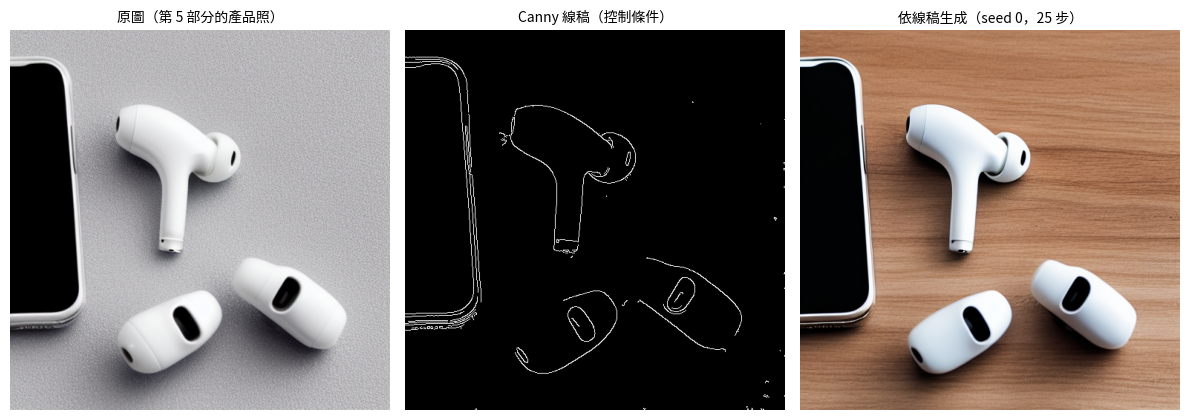

ControlNet 生成 6.6s｜VRAM 峰值 4.18 GB


In [16]:
# 講師示範：ControlNet（Canny 邊緣）。需要第 1 格（環境）和第 5 部分的 product 照片
import cv2
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, UniPCMultistepScheduler

try:
    demo.close()                       # 關掉第 7 部分的 Gradio，釋放資源
except Exception:
    pass
for name in ("i2i", "pipe", "inpaint"):
    globals().pop(name, None)
gc.collect(); torch.cuda.empty_cache() if device == "cuda" else None

src = (product if "product" in globals() else Image.open("product.png")).convert("RGB").resize((512, 512))
edges = cv2.Canny(np.array(src), 100, 200)                 # 線稿：白線、黑底
sketch = Image.fromarray(np.stack([edges] * 3, axis=-1))

controlnet = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=dtype)
cn = StableDiffusionControlNetPipeline.from_pretrained(MODEL, controlnet=controlnet, torch_dtype=dtype,
                                                       safety_checker=None).to(device)
cn.scheduler = UniPCMultistepScheduler.from_config(cn.scheduler.config)
cn.set_progress_bar_config(disable=True)

CN_PROMPT = ("product photo of white wireless earbuds with charging case on a wooden cafe table, "
             "morning sunlight, shallow depth of field")
CN_STEPS = 25
if device == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
out = cn(CN_PROMPT, image=sketch, num_inference_steps=CN_STEPS, guidance_scale=7.5,
         generator=torch.Generator(device).manual_seed(SEED)).images[0]
sec = time.time() - t0
show_row([src, sketch, out],
         ["原圖（第 5 部分的產品照）", "Canny 線稿（控制條件）", f"依線稿生成（seed {SEED}，{CN_STEPS} 步）"],
         size=4, path="controlnet_demo.png")
print(f"ControlNet 生成 {sec:.1f}s｜VRAM 峰值 {vram()}")